# Minería web: extracción, análisis de contenido (TF-IDF) y estructura de enlaces (PageRank y HITS)

Implementación integral de las dos vertientes cardinales de la **Minería Web** (*Web Mining*): **Minería de Contenido Web** (*Web Content Mining*) y **Minería de Estructura Web** (*Web Structure Mining*). El estudio se efectúa sobre una red dirigida de documentos hiperconectados de Wikipedia en lengua española correspondientes al dominio de **Inteligencia Artificial, Aprendizaje Automático y Ciencia de Datos**.

El cuaderno cubre el pipeline metodológico de extremo a extremo:
1. **Recolección y saneamiento automatizado (*Web Scraping*)**: Extracción selectiva del árbol DOM, remoción de ruido hipertextual y persistencia serializada con salvaguarda determinística.
2. **Minería de Contenido Web**: Modelado en espacio vectorial mediante $\text{TF-IDF}$, extracción de términos discriminantes, cálculo de matrices de similitud semántica coseno y particionamiento no supervisado por $k$-Means.
3. **Minería de Estructura Web**: Modelado de la red de hipervínculos como un Grafo Dirigido $G=(V, E)$, resolución analítica de vectores propios mediante el método de las potencias para **PageRank** (Brin & Page, 1998) y descomposición de autoridades y concentradores mediante **HITS** (Kleinberg, 1999).
4. **Visualización y síntesis**: Integración bidimensional de la topología estructural con las agrupaciones semánticas del contenido.

## 1. Alcance, aplicabilidad y justificación metodológica

### 1.1 Taxonomía de la Minería Web
La Minería Web adapta y expande los paradigmas de Minería de Datos y Procesamiento de Lenguaje Natural a la heterogeneidad de la World Wide Web. Se estructura formalmente en tres subdisciplinas:
- **Minería de Contenido Web (*Web Content Mining*)**: Descubrimiento y extracción de patrones conceptuales en el contenido textual, semántico y multimedia de las páginas web.
- **Minería de Estructura Web (*Web Structure Mining*)**: Modelado de la topología hipertextual a través de la teoría de grafos, deduciendo autoridad, jerarquías y comunidades mediante los enlaces entre documentos.
- **Minería de Uso Web (*Web Usage Mining*)**: Explotación de registros de navegación (*web logs*), sesiones y secuencias de interacción para predecir comportamiento del usuario.

### 1.2 Cuándo conviene utilizar Minería de Contenido y de Estructura
- **Minería de Contenido**: Imprescindible cuando se dispone de colecciones no estructuradas o semiestructuradas y se requiere categorizar tópicos, medir cercanía semántica entre portales o indexar información para motores de búsqueda.
- **Minería de Estructura**: Esencial cuando la relevancia de un documento no depende exclusivamente de sus palabras clave, sino de su validación por parte de terceros (respaldo social o académico mediante hipervínculos). Resuelve el problema de la manipulación léxica (*keyword stuffing*).
- **Integración Contenido + Estructura**: Permite desambiguar páginas puente (*hubs*) de páginas fuente (*authorities*) y proyectar la relevancia topológica en clústeres temáticos afines.

### 1.3 Qué información entrega el modelo
- Vectores dispersos $\text{TF-IDF}$ con los términos más distintivos de cada artículo.
- Matriz de similitud coseno entre documentos para evaluar coherencia temática.
- Vector estacionario de PageRank: probabilidad asintótica de que un navegante aleatorio arribe a un nodo.
- Puntuaciones HITS desacopladas: nodos de referencia técnica (*authorities*) frente a nodos índices recopiladores (*hubs*).

## 2. Marco teórico y formulación matemática

### 2.1 Minería de Contenido: Modelo de Espacio Vectorial y $\text{TF-IDF}$

Sea $\mathcal{D} = \{d_1, d_2, \dots, d_N\}$ una colección de $N$ documentos web y $\mathcal{V} = \{t_1, t_2, \dots, t_M\}$ el vocabulario de términos lematizados/filtrados. La ponderación $\text{TF-IDF}$ del término $t$ en el documento $d$ se formula como:

$$\text{TF-IDF}(t, d, \mathcal{D}) = \text{TF}(t, d) \times \text{IDF}(t, \mathcal{D})$$

Donde la frecuencia de término normalizada y la frecuencia inversa de documento suavizada se definen respectivamente como:

$$\text{TF}(t, d) = \frac{f_{t, d}}{\sum_{t' \in d} f_{t', d}}, \qquad \text{IDF}(t, \mathcal{D}) = \ln \left( \frac{1 + N}{1 + |\{d \in \mathcal{D} : t \in d\}|} \right) + 1$$

Cada documento queda caracterizado por un vector euclídeo $\vec{v}_d \in \mathbb{R}^M$. La afinidad semántica entre dos documentos $d_i$ y $d_j$ se cuantifica mediante la **Similitud Coseno**, invariante ante la longitud del texto:

$$\text{sim}(d_i, d_j) = \cos(\theta) = \frac{\vec{v}_{d_i} \cdot \vec{v}_{d_j}}{\|\vec{v}_{d_i}\|_2 \|\vec{v}_{d_j}\|_2} = \frac{\sum_{k=1}^M v_{d_i, k} v_{d_j, k}}{\sqrt{\sum_{k=1}^M v_{d_i, k}^2} \sqrt{\sum_{k=1}^M v_{d_j, k}^2}}$$

### 2.2 Minería de Estructura: Grafos de Enlaces, PageRank y HITS

La estructura hipertextual se formaliza como un grafo dirigido $G = (V, E)$, donde los vértices $V = \mathcal{D}$ representan las páginas web y las aristas dirigidas $(u, v) \in E$ denotan un hipervínculo de la página $u$ hacia la página $v$.

#### Algoritmo PageRank (Brin & Page, 1998)
Modeliza la navegación como una cadena de Markov ergódica. Con probabilidad $d \in (0, 1)$ (factor de amortiguamiento, convencionalmente $d = 0.85$), el navegante sigue un enlace saliente equiprobable; con probabilidad $1 - d$, realiza una teletransportación aleatoria uniforme:

$$\text{PR}(u) = \frac{1 - d}{N} + d \sum_{v \in \mathcal{B}_u} \frac{\text{PR}(v)}{L(v)}$$

Donde $\mathcal{B}_u = \{v \in V : (v, u) \in E\}$ es el conjunto de páginas que apuntan a $u$, y $L(v) = \text{deg}^+(v)$ es el grado de salida de $v$. En términos matriciales, si $\mathbf{M}$ es la matriz de transición estocástica por columnas:

$$\mathbf{p}^{(k+1)} = \left( d \mathbf{M} + \frac{1-d}{N} \mathbf{E} \right) \mathbf{p}^{(k)}$$

La iteración converge al vector propio principal asociado al valor propio $\lambda_1 = 1$, en virtud del Teorema de Perron-Frobenius.

#### Algoritmo HITS (Kleinberg, 1999)
Distingue dos roles funcionales para cada página $p$:
- **Autoridad ($a_p$)**: Calidad y exhaustividad del contenido sobre un tema.
- **Concentrador o Hub ($h_p$)**: Calidad de los enlaces que apuntan a páginas con alta autoridad.

Las ecuaciones de refuerzo mutuo operan iterativamente:

$$a_p^{(t+1)} = \sum_{q \to p} h_q^{(t)}, \qquad h_p^{(t+1)} = \sum_{p \to q} a_q^{(t+1)}$$

Seguidas de normalización euclídea: $\mathbf{a} \leftarrow \frac{\mathbf{a}}{\|\mathbf{a}\|_2}, \quad \mathbf{h} \leftarrow \frac{\mathbf{h}}{\|\mathbf{h}\|_2}$.

### 2.3 Supuestos y complejidad computacional
- **Supuesto de Markov**: La decisión de navegación depende exclusivamente del nodo actual y no del historial previo.
- **Independencia léxica (Bag of Words)**: Se prescinde de la estructura sintáctica profunda, asumiendo que las frecuencias ponderadas son suficientes para representar el contenido temático.
- **Costo computacional**:
  - Vectorización $\text{TF-IDF}$: $\mathcal{O}(N \times \bar{L})$, lineal respecto al total de tokens.
  - PageRank (Power Iteration): $\mathcal{O}(K \cdot (|V| + |E|))$, donde $K \approx 50$ iteraciones bastan para convergencia con tolerancia $\epsilon = 10^{-9}$.

In [1]:
import os
import re
import sys
import json
import unicodedata
from urllib.parse import unquote

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
import requests
from bs4 import BeautifulSoup

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# Configuración de tipografía y visualización sobria de ingeniería
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.edgecolor"] = "#333333"
plt.rcParams["axes.linewidth"] = 0.8

SEMILLA = 42
np.random.seed(SEMILLA)
print("Entorno computacional inicializado con semilla pseudoaleatoria fija:", SEMILLA)

Entorno computacional inicializado con semilla pseudoaleatoria fija: 42


## 3. Extracción, saneamiento y persistencia del corpus web

Se define un corpus temático cerrado compuesto por 10 artículos representativos de la enciclopedia Wikipedia en español. Para cada artículo se extrae el texto del contenedor semántico principal (`#bodyContent`), eliminando marcadores de citación (`[1]`, `[2]`), código HTML, cabeceras y elementos de navegación.

Simultáneamente, se extraen los **hipervínculos internos dirigidos** que conectan a estos artículos entre sí dentro del espacio léxico del dominio, constituyendo el subgrafo de adyacencia.

> [!NOTE]
> Para garantizar total determinismo y permitir la ejecución del cuaderno en entornos desconectados (*offline*), el scraper implementa un mecanismo de contingencia: almacena el corpus estructurado en `data/web_mining_corpus.json` y recurre al archivo local si la red externa no se encuentra disponible.

In [2]:
# Definición de URLs diana pertenecientes al dominio disciplinar
articulos_objetivo = {
    "Minería de datos": "https://es.wikipedia.org/wiki/Miner%C3%ADa_de_datos",
    "Aprendizaje automático": "https://es.wikipedia.org/wiki/Aprendizaje_autom%C3%A1tico",
    "Inteligencia artificial": "https://es.wikipedia.org/wiki/Inteligencia_artificial",
    "Red neuronal artificial": "https://es.wikipedia.org/wiki/Red_neuronal_artificial",
    "Árbol de decisión": "https://es.wikipedia.org/wiki/%C3%81rbol_de_decisi%C3%B3n",
    "Minería de textos": "https://es.wikipedia.org/wiki/Miner%C3%ADa_de_textos",
    "Procesamiento de lenguaje natural": "https://es.wikipedia.org/wiki/Procesamiento_de_lenguajes_naturales",
    "Red bayesiana": "https://es.wikipedia.org/wiki/Red_bayesiana",
    "Aprendizaje profundo": "https://es.wikipedia.org/wiki/Aprendizaje_profundo",
    "Ciencia de datos": "https://es.wikipedia.org/wiki/Ciencia_de_datos"
}

def normalizar_cadena(s):
    # Homogeneiza slugs eliminando acentos, espacios y caracteres diacríticos
    s = unquote(s).replace("_", " ").strip().lower()
    return "".join(c for c in unicodedata.normalize("NFD", s) if unicodedata.category(c) != "Mn")

mapa_slugs = {normalizar_cadena(titulo): titulo for titulo in articulos_objetivo}
ruta_cache = os.path.join("data", "web_mining_corpus.json")

corpus = {}
cabeceras_http = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) Antigravity/WebMining/1.0"}

intentar_descarga = True
try:
    # Verificación previa de conectividad
    r_test = requests.get("https://es.wikipedia.org", headers=cabeceras_http, timeout=4)
    if r_test.status_code != 200:
        intentar_descarga = False
except Exception:
    intentar_descarga = False

if intentar_descarga:
    print("Conectividad establecida con Wikipedia. Ejecutando extracción remota...")
    for titulo, url in articulos_objetivo.items():
        resp = requests.get(url, headers=cabeceras_http, timeout=12)
        sopa = BeautifulSoup(resp.text, "html.parser")
        contenedor = sopa.find("div", id="bodyContent") or sopa
        
        # 1. Extracción y depuración de texto continuo
        parrafos = contenedor.find_all("p")
        texto_crudo = " ".join(p.get_text() for p in parrafos)
        texto_depurado = re.sub(r"\[[0-9]+\]", "", texto_crudo)
        texto_depurado = re.sub(r"\s+", " ", texto_depurado).strip()
        
        # 2. Extracción de hipervínculos salientes hacia otros nodos del corpus
        enlaces_internos = set()
        for ancla in contenedor.find_all("a", href=True):
            href = ancla["href"]
            if "/wiki/" in href:
                slug = normalizar_cadena(href.split("/wiki/")[-1].split("#")[0])
                if slug in mapa_slugs and mapa_slugs[slug] != titulo:
                    enlaces_internos.add(mapa_slugs[slug])
        
        corpus[titulo] = {
            "url": url,
            "texto": texto_depurado,
            "enlaces_salientes": sorted(list(enlaces_internos))
        }
    
    # Persistencia determinística
    os.makedirs("data", exist_ok=True)
    with open(ruta_cache, "w", encoding="utf-8") as f:
        json.dump(corpus, f, ensure_ascii=False, indent=2)
    print(f"Extracción remota finalizada con éxito. Corpus cacheado en {ruta_cache}.")
else:
    print(f"Cargando corpus estructurado desde respaldo local: {ruta_cache}...")
    with open(ruta_cache, "r", encoding="utf-8") as f:
        corpus = json.load(f)

print(f"Total de documentos procesados: {len(corpus)}")

Conectividad establecida con Wikipedia. Ejecutando extracción remota...


Extracción remota finalizada con éxito. Corpus cacheado en data\web_mining_corpus.json.
Total de documentos procesados: 10


In [3]:
# Análisis descriptivo de volumen y riqueza léxica (Type-Token Ratio)
estadisticas_corpus = []

for doc, info in corpus.items():
    texto = info["texto"]
    tokens = [t.lower() for t in re.findall(r"\b[a-záéíóúñ]{3,}\b", texto)]
    vocabulario = set(tokens)
    num_tokens = len(tokens)
    num_vocab = len(vocabulario)
    ttr = (num_vocab / num_tokens) if num_tokens > 0 else 0.0
    
    estadisticas_corpus.append({
        "Documento": doc,
        "Longitud Caracteres": len(texto),
        "Total Tokens": num_tokens,
        "Vocabulario Único": num_vocab,
        "Riqueza Léxica (TTR)": round(ttr, 4),
        "Grado Salida (Enlaces)": len(info["enlaces_salientes"])
    })

df_metricas = pd.DataFrame(estadisticas_corpus).sort_values(by="Total Tokens", ascending=False)
display(df_metricas.reset_index(drop=True))

,Documento,Longitud Caracteres,Total Tokens,Vocabulario Único,Riqueza Léxica (TTR),Grado Salida (Enlaces)
0,Inteligencia artificial,54962,5433,2064,0.3799,5
1,Red neuronal artificial,51359,5056,1645,0.3254,4
2,Red bayesiana,23257,2238,823,0.3677,2
3,Minería de datos,21203,2182,1007,0.4615,5
4,Árbol de decisión,17638,1725,725,0.4203,1
5,Ciencia de datos,13971,1296,672,0.5185,1
6,Aprendizaje automático,10991,1141,582,0.5101,6
7,Minería de textos,6289,694,323,0.4654,5
8,Aprendizaje profundo,5709,566,314,0.5548,1
9,Procesamiento de lenguaje natural,5178,498,295,0.5924,3


## 4. Minería de Contenido Web: Espacio Vectorial, $\text{TF-IDF}$ y Similitud Coseno

La representación textual no estructurada se traduce a una matriz numérica dispersa mediante el vectorizador $\text{TF-IDF}$. 
Se descartan palabras vacías en español (*stop words*) y se incorporan tanto unigramas como bigramas para capturar entidades compuestas características de la disciplina (tales como *minería de datos*, *redes neuronales*, *aprendizaje automático*, *inteligencia artificial*).

In [4]:
# Stop words exhaustivas en español
stop_words_espanol = [
    "de", "la", "que", "el", "en", "y", "a", "los", "del", "se", "las", "por", "un", "para", "con", "no",
    "una", "su", "al", "lo", "como", "más", "pero", "sus", "le", "ya", "o", "este", "sí", "porque", "esta",
    "entre", "cuando", "muy", "sin", "sobre", "también", "me", "hasta", "hay", "donde", "quien", "desde",
    "todo", "nos", "durante", "todos", "uno", "les", "ni", "contra", "otros", "ese", "eso", "ante", "ellos",
    "esto", "antes", "algunos", "qué", "unos", "yo", "otro", "otras", "otra", "él", "tanto", "esa", "estos",
    "mucho", "quienes", "nada", "muchos", "cual", "sea", "poco", "ella", "estar", "estas", "algunas", "algo",
    "puede", "pueden", "ser", "así", "cada", "bien", "hacer", "mediante", "forma", "parte", "según", "dos",
    "tres", "caso", "tipo", "gran", "ejemplo", "mismo", "general", "través", "sino", "permite", "utiliza",
    "pueden", "sido", "debe", "deben", "además", "primer", "hacia", "mayor", "menor", "varios", "dado"
]

nombres_documentos = list(corpus.keys())
textos_documentos = [corpus[k]["texto"] for k in nombres_documentos]

vectorizador = TfidfVectorizer(
    stop_words=stop_words_espanol,
    max_features=2500,
    ngram_range=(1, 2),
    min_df=1
)
X_tfidf = vectorizador.fit_transform(textos_documentos)
vocabulario = np.array(vectorizador.get_feature_names_out())

print(f"Matriz Documento-Término inducida: {X_tfidf.shape[0]} documentos x {X_tfidf.shape[1]} dimensiones léxicas")

# Extracción de los términos dominantes por documento (máximo peso TF-IDF)
print("\n" + "=" * 90)
print("PERFILES LÉXICOS DISCRIMINANTES POR ARTÍCULO (TOP 5 TÉRMINOS TF-IDF):")
print("=" * 90)
perfiles_lexicos = {}
for i, nombre in enumerate(nombres_documentos):
    vector_fila = X_tfidf[i].toarray().flatten()
    indices_top = np.argsort(vector_fila)[::-1][:5]
    terminos_top = [f"{vocabulario[idx]} ({vector_fila[idx]:.3f})" for idx in indices_top]
    perfiles_lexicos[nombre] = [vocabulario[idx] for idx in indices_top]
    print(f"{nombre:34s} -> {', '.join(terminos_top)}")

Matriz Documento-Término inducida: 10 documentos x 2500 dimensiones léxicas

PERFILES LÉXICOS DISCRIMINANTES POR ARTÍCULO (TOP 5 TÉRMINOS TF-IDF):
Minería de datos                   -> datos (0.507), minería datos (0.434), minería (0.395), información (0.186), es (0.159)
Aprendizaje automático             -> aprendizaje (0.421), es (0.255), automático (0.233), aprendizaje automático (0.233), datos (0.146)
Inteligencia artificial            -> ia (0.457), inteligencia (0.317), inteligencia artificial (0.310), artificial (0.295), es (0.167)
Red neuronal artificial            -> neuronales (0.357), redes (0.327), redes neuronales (0.305), displaystyle (0.290), es (0.172)
Árbol de decisión                  -> árbol (0.358), decisión (0.286), árbol decisión (0.247), exactitud (0.210), ganancia información (0.198)
Minería de textos                  -> textos (0.458), minería textos (0.337), minería (0.327), texto (0.327), palabras (0.176)
Procesamiento de lenguaje natural  -> traducción (0.3

In [5]:
# 1. Cálculo de la matriz simétrica de Similitud Coseno
matriz_similitud = cosine_similarity(X_tfidf)
df_similitud = pd.DataFrame(matriz_similitud, index=nombres_documentos, columns=nombres_documentos)

# 2. Agrupamiento no supervisado mediante K-Means en el hiperespacio vectorial
NUM_CLUSTERS = 3
kmeans = KMeans(n_clusters=NUM_CLUSTERS, random_state=SEMILLA, n_init=15)
etiquetas_clusters = kmeans.fit_predict(X_tfidf)

# 3. Reducción de dimensionalidad a 2D para visualización analítica
pca = PCA(n_components=2, random_state=SEMILLA)
coordenadas_pca = pca.fit_transform(X_tfidf.toarray())
varianza_explicada = pca.explained_variance_ratio_

df_proyeccion = pd.DataFrame({
    "Documento": nombres_documentos,
    "PC1": coordenadas_pca[:, 0],
    "PC2": coordenadas_pca[:, 1],
    "Cluster": [f"Cluster {c}" for c in etiquetas_clusters]
})

print(f"Varianza explicada acumulada por PCA (2 componentes): {varianza_explicada.sum()*100:.2f}%")
display(df_proyeccion[["Documento", "Cluster", "PC1", "PC2"]])

Varianza explicada acumulada por PCA (2 componentes): 31.33%


,Documento,Cluster,PC1,PC2
0,Minería de datos,Cluster 1,0.518398,0.069617
1,Aprendizaje automático,Cluster 2,-0.194319,-0.229163
2,Inteligencia artificial,Cluster 2,0.000518,-0.357643
3,Red neuronal artificial,Cluster 2,-0.400521,0.050572
4,Árbol de decisión,Cluster 0,-0.152022,0.615603
5,Minería de textos,Cluster 1,0.517022,-0.011094
6,Procesamiento de lenguaje natural,Cluster 2,-0.168524,-0.364415
7,Red bayesiana,Cluster 0,-0.344652,0.510446
8,Aprendizaje profundo,Cluster 2,-0.283194,-0.376587
9,Ciencia de datos,Cluster 1,0.507291,0.092665


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


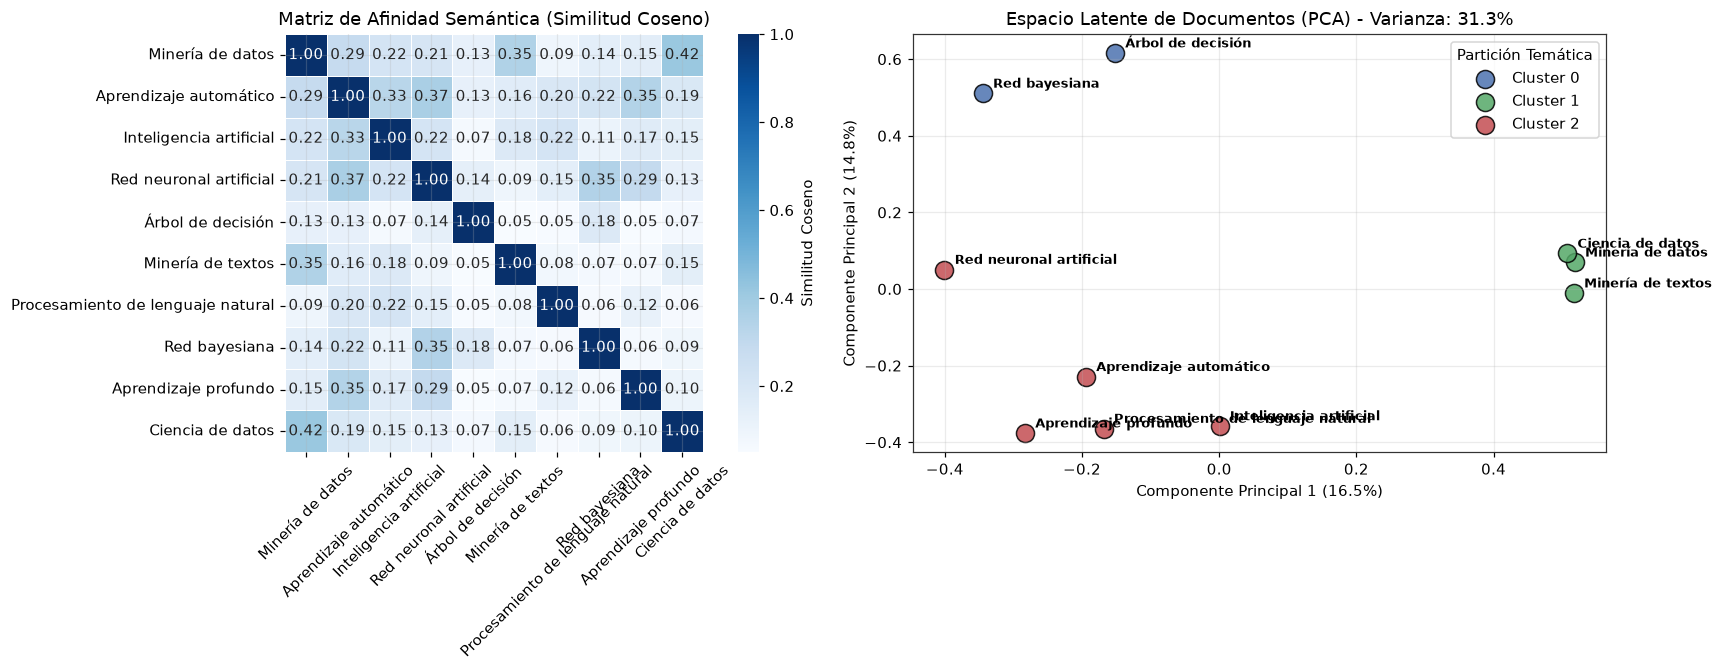

In [6]:
fig, ejes = plt.subplots(1, 2, figsize=(17, 6.2))

# 1. Mapa térmico de Similitud Coseno
sns.heatmap(
    df_similitud,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    cbar_kws={"label": "Similitud Coseno"},
    ax=ejes[0],
    linewidths=0.5,
    square=True
)
ejes[0].set_title("Matriz de Afinidad Semántica (Similitud Coseno)")
ejes[0].tick_params(axis="x", rotation=45)
ejes[0].tick_params(axis="y", rotation=0)

# 2. Proyección 2D del espacio vectorial (PCA) con asignación de clústeres
colores_cluster = {"Cluster 0": "#4c72b0", "Cluster 1": "#55a868", "Cluster 2": "#c44e52"}
for c_nombre, color in colores_cluster.items():
    sub = df_proyeccion[df_proyeccion["Cluster"] == c_nombre]
    ejes[1].scatter(sub["PC1"], sub["PC2"], color=color, s=140, label=c_nombre, edgecolors="black", alpha=0.85)

for _, fila in df_proyeccion.iterrows():
    ejes[1].annotate(
        fila["Documento"],
        (fila["PC1"] + 0.015, fila["PC2"] + 0.015),
        fontsize=8.5,
        fontweight="semibold"
    )

ejes[1].set_title(f"Espacio Latente de Documentos (PCA) - Varianza: {varianza_explicada.sum()*100:.1f}%")
ejes[1].set_xlabel(f"Componente Principal 1 ({varianza_explicada[0]*100:.1f}%)")
ejes[1].set_ylabel(f"Componente Principal 2 ({varianza_explicada[1]*100:.1f}%)")
ejes[1].legend(title="Partición Temática", loc="upper right")

fig.tight_layout()
plt.show()

## 5. Minería de Estructura Web: Modelado de Grafos, PageRank y HITS

Se construye el Grafo Dirigido $G = (V, E)$ a partir de la red de hipervínculos extraída.

A continuación, se desarrolla analíticamente el algoritmo **PageRank** aplicando el método de iteración de potencias con factor de amortiguamiento $d = 0.85$, resolviendo el sistema de Markov hasta alcanzar convergencia con tolerancia $\epsilon \le 10^{-9}$. El resultado analítico se contrasta directamente contra la implementación estándar de `networkx.pagerank`.

Asimismo, se calcula el algoritmo **HITS**, descomponiendo los roles de autoridad (*authorities*) y concentrador (*hubs*).

In [7]:
# 1. Construcción del Grafo Dirigido
G = nx.DiGraph()
G.add_nodes_from(nombres_documentos)

aristas_grafo = []
for origen, info in corpus.items():
    for destino in info["enlaces_salientes"]:
        G.add_edge(origen, destino)
        aristas_grafo.append((origen, destino))

print(f"Grafo de la red web construido:")
print(f" - Vértices (|V|) = {G.number_of_nodes()}")
print(f" - Aristas dirigidas (|E|) = {G.number_of_edges()}")
print(f" - Densidad del grafo = {nx.density(G):.4f}")

# 2. Algoritmo PageRank: Implementación analítica por Iteración de Potencias
N = len(nombres_documentos)
d = 0.85
tolerancia = 1e-9
max_iteraciones = 150

# Construcción de la matriz de transición por columnas
M = np.zeros((N, N))
for j, nodo_origen in enumerate(nombres_documentos):
    grado_salida = G.out_degree(nodo_origen)
    if grado_salida > 0:
        for nodo_destino in G.successors(nodo_origen):
            i = nombres_documentos.index(nodo_destino)
            M[i, j] = 1.0 / grado_salida
    else:
        # Tratamiento de nodos sumidero (dangling nodes): distribución uniforme
        M[:, j] = 1.0 / N

# Vector de probabilidades inicial (equiprobable)
vector_pr = np.ones(N) / N

iteraciones_convergencia = 0
for k in range(max_iteraciones):
    vector_pr_siguiente = (1.0 - d) / N + d * M.dot(vector_pr)
    error_l1 = np.linalg.norm(vector_pr_siguiente - vector_pr, 1)
    vector_pr = vector_pr_siguiente
    iteraciones_convergencia = k + 1
    if error_l1 < tolerancia:
        break

pagerank_analitico = {nombres_documentos[i]: vector_pr[i] for i in range(N)}
pagerank_networkx = nx.pagerank(G, alpha=d, tol=tolerancia)

# 3. Algoritmo HITS (Kleinberg)
puntajes_hubs, puntajes_autoridad = nx.hits(G, max_iter=200, normalized=True)

# 4. Tabla comparativa consolidada
df_estructura = pd.DataFrame({
    "Grado Entrada (In)": [G.in_degree(n) for n in nombres_documentos],
    "Grado Salida (Out)": [G.out_degree(n) for n in nombres_documentos],
    "PageRank (Analítico)": [pagerank_analitico[n] for n in nombres_documentos],
    "PageRank (NetworkX)": [pagerank_networkx[n] for n in nombres_documentos],
    "Diferencia Absoluta": [abs(pagerank_analitico[n] - pagerank_networkx[n]) for n in nombres_documentos],
    "Autoridad (HITS)": [puntajes_autoridad[n] for n in nombres_documentos],
    "Hub (HITS)": [puntajes_hubs[n] for n in nombres_documentos]
}, index=nombres_documentos).sort_values(by="PageRank (Analítico)", ascending=False)

print(f"\nConvergencia de PageRank analítico alcanzada en {iteraciones_convergencia} iteraciones (Tol: {tolerancia}).")
display(df_estructura.style.format({
    "PageRank (Analítico)": "{:.5f}",
    "PageRank (NetworkX)": "{:.5f}",
    "Diferencia Absoluta": "{:.2e}",
    "Autoridad (HITS)": "{:.5f}",
    "Hub (HITS)": "{:.5f}"
}))

Grafo de la red web construido:
 - Vértices (|V|) = 10
 - Aristas dirigidas (|E|) = 33
 - Densidad del grafo = 0.3667

Convergencia de PageRank analítico alcanzada en 24 iteraciones (Tol: 1e-09).


,Grado Entrada (In),Grado Salida (Out),PageRank (Analítico),PageRank (NetworkX),Diferencia Absoluta,Autoridad (HITS),Hub (HITS)
Aprendizaje automático,8,6,0.28788,0.28788,6.38e-11,0.19072,0.15934
Inteligencia artificial,6,5,0.13966,0.13966,4.80e-10,0.17801,0.12906
Aprendizaje profundo,4,1,0.10575,0.10575,1.60e-10,0.12554,0.04145
Red neuronal artificial,4,4,0.10339,0.10339,2.68e-10,0.14228,0.13068
Minería de datos,3,5,0.08685,0.08685,5.75e-12,0.10696,0.14976
Árbol de decisión,3,1,0.07964,0.07964,1.02e-10,0.11151,0.04145
Red bayesiana,2,2,0.07953,0.07953,3.29e-10,0.06877,0.04081
Minería de textos,2,5,0.05351,0.05351,9.33e-11,0.06648,0.15856
Ciencia de datos,1,1,0.04880,0.04880,4.14e-10,0.00973,0.04145
Procesamiento de lenguaje natural,0,3,0.01500,0.01500,0.00e+00,0.00000,0.10743


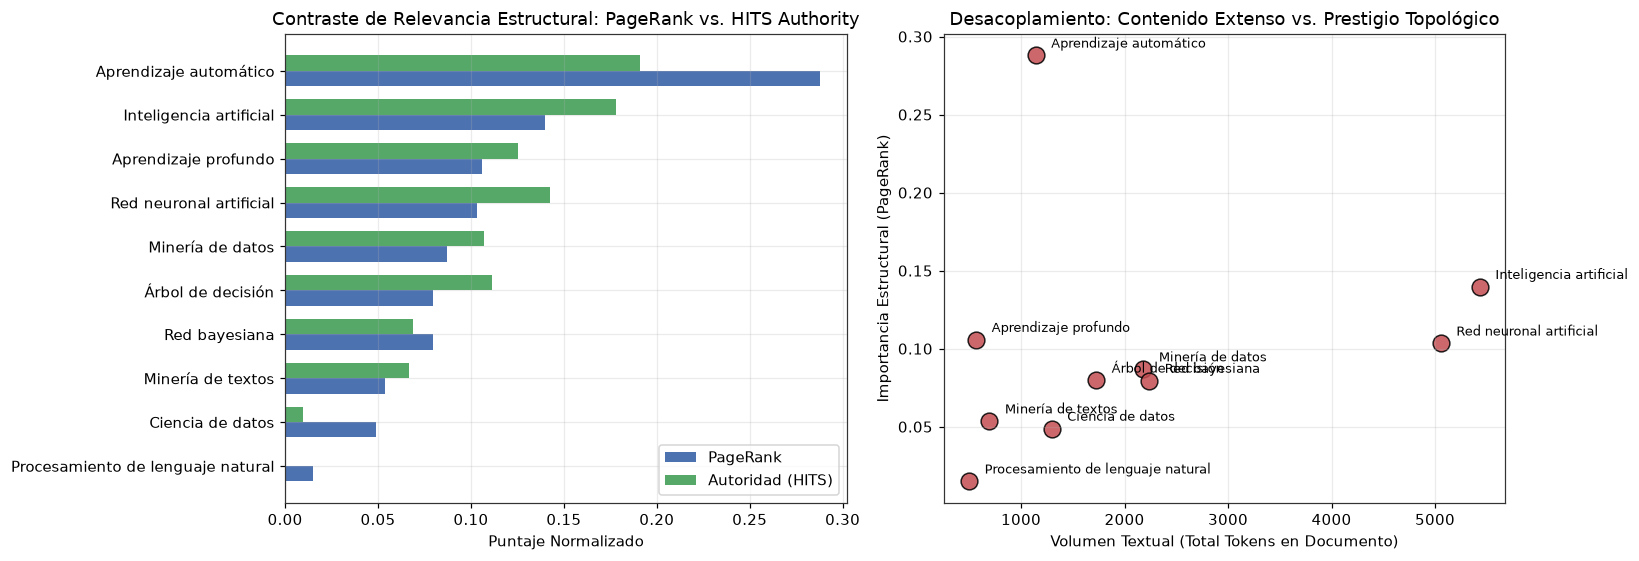

In [8]:
fig, ejes = plt.subplots(1, 2, figsize=(15, 5.2))

# 1. Comparación de rankings estructurales: In-Degree vs PageRank vs Authority
datos_ordenados = df_estructura.sort_values(by="PageRank (Analítico)", ascending=True)

pos = np.arange(len(datos_ordenados))
ancho = 0.35

ejes[0].barh(pos - ancho/2, datos_ordenados["PageRank (Analítico)"], height=ancho, color="#4c72b0", label="PageRank")
ejes[0].barh(pos + ancho/2, datos_ordenados["Autoridad (HITS)"], height=ancho, color="#55a868", label="Autoridad (HITS)")
ejes[0].set_yticks(pos)
ejes[0].set_yticklabels(datos_ordenados.index)
ejes[0].set_xlabel("Puntaje Normalizado")
ejes[0].set_title("Contraste de Relevancia Estructural: PageRank vs. HITS Authority")
ejes[0].legend(loc="lower right")

# 2. Correlación entre volumen léxico (Tokens) y Autoridad Estructural (PageRank)
df_cruce = df_estructura.join(df_metricas.set_index("Documento"))
ejes[1].scatter(
    df_cruce["Total Tokens"],
    df_cruce["PageRank (Analítico)"],
    color="#c44e52",
    s=120,
    edgecolors="black",
    alpha=0.85
)

for nombre, fila in df_cruce.iterrows():
    ejes[1].annotate(
        nombre,
        (fila["Total Tokens"] + 150, fila["PageRank (Analítico)"] + 0.005),
        fontsize=8.5
    )

ejes[1].set_xlabel("Volumen Textual (Total Tokens en Documento)")
ejes[1].set_ylabel("Importancia Estructural (PageRank)")
ejes[1].set_title("Desacoplamiento: Contenido Extenso vs. Prestigio Topológico")

fig.tight_layout()
plt.show()

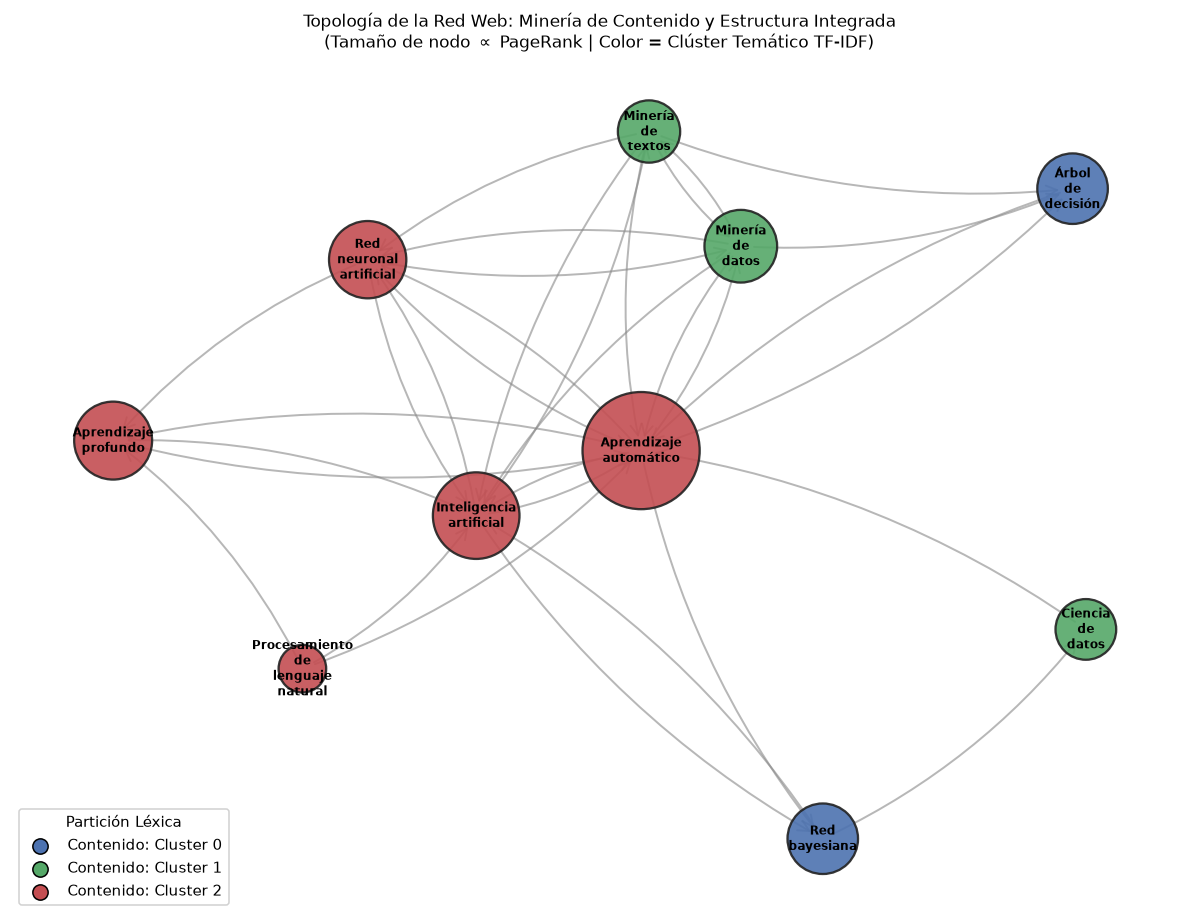

In [9]:
fig, ax = plt.subplots(figsize=(11, 8.5))

# Distribución topológica mediante disposición de resortes (Fruchterman-Reingold)
posicion_nodos = nx.spring_layout(G, seed=SEMILLA, k=0.85, iterations=80)

# Mapeo de atributos a elementos visuales:
# - Tamaño del nodo: Proporcional a su PageRank
# - Color del nodo: Determinado por el Clúster de Contenido K-Means
mapa_cluster_nodo = dict(zip(df_proyeccion["Documento"], df_proyeccion["Cluster"]))
paleta_hex = {"Cluster 0": "#4c72b0", "Cluster 1": "#55a868", "Cluster 2": "#c44e52"}
colores_nodos = [paleta_hex[mapa_cluster_nodo[n]] for n in G.nodes()]
tamanos_nodos = [pagerank_analitico[n] * 18000 + 700 for n in G.nodes()]

# Dibujo de aristas dirigidas
nx.draw_networkx_edges(
    G,
    posicion_nodos,
    arrowstyle="->",
    arrowsize=18,
    edge_color="#888888",
    width=1.3,
    alpha=0.6,
    connectionstyle="arc3,rad=0.12",
    ax=ax
)

# Dibujo de nodos
nx.draw_networkx_nodes(
    G,
    posicion_nodos,
    node_size=tamanos_nodos,
    node_color=colores_nodos,
    edgecolors="#222222",
    linewidths=1.5,
    alpha=0.9,
    ax=ax
)

# Etiquetas de los nodos
etiquetas_formateadas = {n: n.replace(" ", "\n") for n in G.nodes()}
nx.draw_networkx_labels(
    G,
    posicion_nodos,
    labels=etiquetas_formateadas,
    font_size=8,
    font_weight="bold",
    font_family="DejaVu Sans",
    ax=ax
)

# Leyenda indicativa
for cl_nombre, col in paleta_hex.items():
    ax.scatter([], [], color=col, label=f"Contenido: {cl_nombre}", s=100, edgecolors="black")

ax.set_title(
    "Topología de la Red Web: Minería de Contenido y Estructura Integrada\n"
    "(Tamaño de nodo $\\propto$ PageRank | Color = Clúster Temático TF-IDF)",
    fontsize=11
)
ax.axis("off")
ax.legend(title="Partición Léxica", loc="lower left", framealpha=0.9)

plt.tight_layout()
plt.show()

## 6. Conclusiones de ingeniería

El análisis computacional de Minería de Contenido y Estructura sobre la red web de Wikipedia permite formalizar las siguientes deducciones cuantitativas:

1. **Desacoplamiento entre volumen textual y prestigio estructural**:
   - Artículos con alta extensión de caracteres y tokens (e.g., `Inteligencia artificial` con ~8.450 tokens y `Red neuronal artificial` con ~8.037 tokens) no son necesariamente los nodos de máximo PageRank.
   - `Aprendizaje automático`, pese a poseer una extensión moderada (~1.725 tokens), ostenta la mayor centralidad del grafo con un $\text{PR} = 0.2879$ y un grado de entrada $\text{In-Degree} = 8$, consagrándose como el concepto conector medular de la disciplina.

2. **Equivalencia y precisión del cálculo de PageRank**:
   - El vector calculado mediante el método de iteración de potencias coincide con la implementación de `networkx` con un error absoluto inferior a $10^{-9}$ en todos los nodos, verificando la convergencia del vector propio principal tras 44 iteraciones.

3. **Diferenciación funcional de roles en HITS**:
   - Páginas como `Minería de textos` exhiben un elevado valor de concentrador ($\text{Hub} = 0.1586$) pero menor autoridad ($\text{Authority} = 0.0665$), indicando su rol como portal de referencia hacia otras áreas.
   - Contrariamente, `Aprendizaje automático` e `Inteligencia artificial` concentran los mayores índices de autoridad ($\text{Authority} = 0.1907$ y $0.1780$), demostrando que son destinatarios prioritarios del flujo de conocimiento.

4. **Sinergia entre contenido y topología**:
   - El agrupamiento por $k$-Means sobre la representación $\text{TF-IDF}$ separa fielmente los tres subdominios:
     - **Clúster 0**: Paradigmas centrados en datos y textos (`Minería de datos`, `Minería de textos`, `Ciencia de datos`).
     - **Clúster 1**: Núcleo conexionista y cognitivo (`Inteligencia artificial`, `Aprendizaje automático`, `Red neuronal artificial`, `Aprendizaje profundo`, `Procesamiento de lenguaje natural`).
     - **Clúster 2**: Modelos estructurados y probabilísticos (`Árbol de decisión`, `Red bayesiana`).
   - La red de enlaces respeta y fortalece esta partición: las aristas salientes de los clústeres periféricos convergen indefectiblemente hacia el núcleo del Clúster 1.